PLEASE REFER TO APPENDIX ON HOW TO RUN THE CODE, CHANGE THE FILE NAMES ACCORDINGLY IN ORDER FOR THE DATASETS TO BE IMPORTED ON YOUR SYSTEM. YOU CAN LOCATE THE WHEREABOUTS OF THE CSV'S BY CHECKING THE PATHWAY WHERE THE CODE IS TRYING TO IMPORT


USE localized_url function if there's an error with the imports

In [ ]:
import os
def localized_url(url):

    current_dir = os.getcwd().split("statistical-analysis-and-modeling-of-football-data")[0] + "statistical-analysis-and-modeling-of-football-data"
    branch = url.split("statistical-analysis-and-modeling-of-football-data")[1]
    return current_dir + branch

In [265]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#import linear regression model
from sklearn.linear_model import LinearRegression
from tqdm import tqdm
from statsmodels.tsa.holtwinters import Holt
import re

In [ ]:
import os
def localized_url(url):

    current_dir = os.getcwd().split("statistical-analysis-and-modeling-of-football-data")[0] + "statistical-analysis-and-modeling-of-football-data"
    branch = url.split("statistical-analysis-and-modeling-of-football-data")[1]
    return current_dir + branch

In [ ]:
match_df = pd.read_csv(localized_url('/Users/yarkin/Desktop/Dissertation/statistical-analysis-and-modeling-of-football-data/Understat/Data/understat_match_1524.csv'))


In [267]:
match_df.columns

Index(['id', 'fid', 'h', 'a', 'date', 'league_id', 'season', 'h_goals',
       'a_goals', 'team_h', 'team_a', 'h_xg', 'a_xg', 'h_w', 'h_d', 'h_l',
       'league', 'h_shot', 'a_shot', 'h_shotOnTarget', 'a_shotOnTarget',
       'h_deep', 'a_deep', 'a_ppda', 'h_ppda'],
      dtype='object')

In [268]:
team_stats= match_df[["id", "h", "a", "date", 'h_goals',
       'a_goals', 'h_xg', 'a_xg', 'h_w', 'h_d', 'h_l',
        'h_shot', 'a_shot', 'h_shotOnTarget', 'a_shotOnTarget',
       'h_deep', 'a_deep', 'a_ppda', 'h_ppda']]

In [269]:
def pivot_match_df(df):
    # Home team perspective
    home_df = df[[
        'id', 'date', 'h', 'h_shotOnTarget', 'h_deep', 'h_ppda'
    ]].copy()
    home_df.rename(columns={
        'h': 'team_id',
        'h_shotOnTarget': 'Shots On Target',
        'h_deep': 'DEEP',
        'h_ppda': 'PPDA'
        
    }, inplace=True)
    home_df["h_a"] = "h"
    # Away team perspective
    away_df = df[[
        'id', 'date', 'a', 'a_shotOnTarget', 'a_deep', 'a_ppda'
    ]].copy()
    away_df.rename(columns={
        'a': 'team_id',
        'a_shotOnTarget': 'Shots On Target',
        'a_deep': 'DEEP',
        'a_ppda': 'PPDA',
    }, inplace=True)
    away_df["h_a"] = "a"
    # Combine both
    long_df = pd.concat([home_df, away_df], ignore_index=True)
    return long_df

In [270]:
home_away_df = pivot_match_df(team_stats)[['id', 'team_id', 'h_a']]

In [271]:
team_stats_df= pivot_match_df(team_stats)

In [292]:
team_stats_df.sort_values(by=['id'])

,id,date,team_id,Shots On Target,DEEP,PPDA,h_a
0,81,2015-08-08 15:45:00,89,1,4,13.8261,h
3420,81,2015-08-08 15:45:00,82,4,10,8.2188,a
3421,82,2015-08-08 18:00:00,71,3,2,11.8462,a
1,82,2015-08-08 18:00:00,73,2,11,6.9000,h
2,83,2015-08-08 18:00:00,72,5,5,6.6500,h
...,...,...,...,...,...,...,...
3067,22303,2023-08-27 13:00:00,238,2,3,36.9091,h
6488,22304,2023-08-27 15:30:00,87,4,5,16.0870,a
3068,22304,2023-08-27 15:30:00,86,8,5,10.8095,h
6738,25861,2024-03-13 19:30:00,256,4,1,9.1250,a


In [272]:
team_stats_df.to_csv("Data/under_team_pivoted.csv", index=False)

In [273]:
match_id_list = team_stats_df.id.unique().tolist()
team_id_list = team_stats_df.team_id.unique().tolist()

In [274]:
features_to_aggregate = ["Shots On Target", "DEEP", "PPDA"]

In [275]:
import numpy as np
import pandas as pd
from tqdm import tqdm
from sklearn.linear_model import LinearRegression

def aggregation_with_error_analysis(df, features_to_aggregate, window=5, discrete_features=None):
    """
    Aggregates team match data using:
    - Rolling mean
    - Linear regression
    - Exponential Moving Average (EMA)
    - Weighted Moving Average (WMA)
    - Median Aggregation
    Computes prediction error for each method vs actual value.
    """

    if discrete_features is None:
        discrete_features = ["Shots On Target", "DEEP"]

    methods = ['linear', 'mean', 'ExpoMovingAverage', 'WMA', 'median']

    df = df.copy().sort_values(by=['team_id', 'date']).reset_index(drop=True)

    # Prepare output columns
    for feature in features_to_aggregate:
        for method in methods:
            df[f'{feature}_{method}'] = np.nan
            df[f'{feature}_{method}_error'] = np.nan

    # Process per team
    for team_id, team_df in tqdm(df.groupby('team_id'), desc=f"Aggregating teams (window={window})"):
        team_df = team_df.sort_values('date').copy()
        team_df.reset_index(drop=False, inplace=True)

        for feature in features_to_aggregate:
            preds = {method: [] for method in methods}
            errors = {method: [] for method in methods}

            for i in range(len(team_df)):
                actual = team_df.loc[i, feature]

                # --- Early-game handling ---
                if i == 0:
                    past_values = team_df.loc[:0, feature].astype(float)  # use actual first value
                elif i < window:
                    past_values = team_df.loc[:i-1, feature].astype(float)  # all available past
                else:
                    past_values = team_df.loc[i - window:i - 1, feature].astype(float)  # fixed window

                # --- Handle empty past_values ---
                if past_values.empty:
                    mean_val = linear_val = expo_val = wma_val = median_val = 0
                else:
                    mean_val = past_values.mean()
                    expo_val = past_values.ewm(span=window, adjust=False).mean().iloc[-1]
                    wma_val = np.dot(past_values, np.arange(1, len(past_values) + 1)) / np.sum(np.arange(1, len(past_values) + 1))
                    median_val = past_values.median()

                    # Linear regression if enough points
                    if len(past_values) >= 2:
                        X = np.arange(len(past_values)).reshape(-1, 1)
                        y = past_values.values
                        lin_model = LinearRegression().fit(X, y)
                        linear_val = lin_model.predict(np.array([[len(past_values)]]))[0]
                    else:
                        linear_val = mean_val

                # --- Rounding/clamping for discrete features ---
                if feature in discrete_features:
                    rounded_vals = {
                        'mean': max(0, round(mean_val)),
                        'linear': max(0, round(linear_val)),
                        'ExpoMovingAverage': max(0, round(expo_val)),
                        'WMA': max(0, round(wma_val)),
                        'median': max(0, round(median_val))
                    }
                else:
                    rounded_vals = {
                        'mean': max(0, mean_val),
                        'linear': max(0, linear_val),
                        'ExpoMovingAverage': max(0, expo_val),
                        'WMA': max(0, wma_val),
                        'median': max(0, median_val)
                    }

                # Store predictions & errors
                for method in methods:
                    preds[method].append(rounded_vals[method])
                    errors[method].append(abs(float(actual) - rounded_vals[method]))

            # Assign results back to main DataFrame
            for method in methods:
                df.loc[team_df['index'], f'{feature}_{method}'] = preds[method]
                df.loc[team_df['index'], f'{feature}_{method}_error'] = errors[method]

    return df


In [276]:
aggregated_df = aggregation_with_error_analysis(team_stats_df, features_to_aggregate, window=5)
aggregated_df

Aggregating teams (window=5):   0%|          | 0/33 [00:00<?, ?it/s]

Aggregating teams (window=5): 100%|██████████| 33/33 [00:08<00:00,  3.92it/s]


,id,date,team_id,Shots On Target,DEEP,PPDA,h_a,Shots On Target_linear,Shots On Target_linear_error,Shots On Target_mean,...,PPDA_linear,PPDA_linear_error,PPDA_mean,PPDA_mean_error,PPDA_ExpoMovingAverage,PPDA_ExpoMovingAverage_error,PPDA_WMA,PPDA_WMA_error,PPDA_median,PPDA_median_error
0,82,2015-08-08 18:00:00,71,3,2,11.8462,a,3.0,0.0,3.0,...,11.846200,0.000000,11.846200,0.000000,11.846200,0.000000,11.846200,0.000000,11.84620,0.00000
1,91,2015-08-14 22:45:00,71,1,3,10.0333,h,3.0,2.0,3.0,...,11.846200,1.812900,11.846200,1.812900,11.846200,1.812900,11.846200,1.812900,11.84620,1.81290
2,104,2015-08-22 18:00:00,71,2,6,8.4762,a,0.0,2.0,2.0,...,8.220400,0.255800,10.939750,2.463550,11.241900,2.765700,10.637600,2.161400,10.93975,2.46355
3,113,2015-08-29 18:00:00,71,6,12,8.6364,h,1.0,5.0,2.0,...,6.748567,1.887833,10.118567,1.482167,10.320000,1.683600,9.556900,0.920500,10.03330,1.39690
4,129,2015-09-13 19:00:00,71,4,5,8.4091,a,6.0,2.0,3.0,...,6.951400,1.457700,9.748025,1.338925,9.758800,1.349700,9.188700,0.779600,9.33485,0.92575
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6835,22230,2024-04-20 14:00:00,256,3,6,11.1250,h,4.0,1.0,4.0,...,30.534360,19.409360,17.190180,6.065180,19.214538,8.089538,20.155553,9.030553,14.43480,3.30980
6836,22244,2024-04-27 14:00:00,256,6,6,9.5333,a,4.0,2.0,4.0,...,19.149060,9.615760,17.843760,8.310460,17.384225,7.850925,18.133827,8.600527,14.43480,4.90150
6837,22252,2024-05-03 19:00:00,256,5,3,10.7727,h,5.0,0.0,4.0,...,10.114420,0.658280,16.863460,6.090760,15.964893,5.192193,15.363673,4.590973,11.12500,0.35230
6838,22263,2024-05-11 14:00:00,256,1,5,9.7407,a,4.0,3.0,5.0,...,9.907970,0.167270,14.312120,4.571420,11.876986,2.136286,13.333420,3.592720,10.77270,1.03200


In [277]:
methods = ['mean', 'linear', 'ExpoMovingAverage', 'WMA', 'median']

Aggregating teams (window=3):   0%|          | 0/33 [00:00<?, ?it/s]

Aggregating teams (window=49): 100%|██████████| 33/33 [00:06<00:00,  4.73it/s]


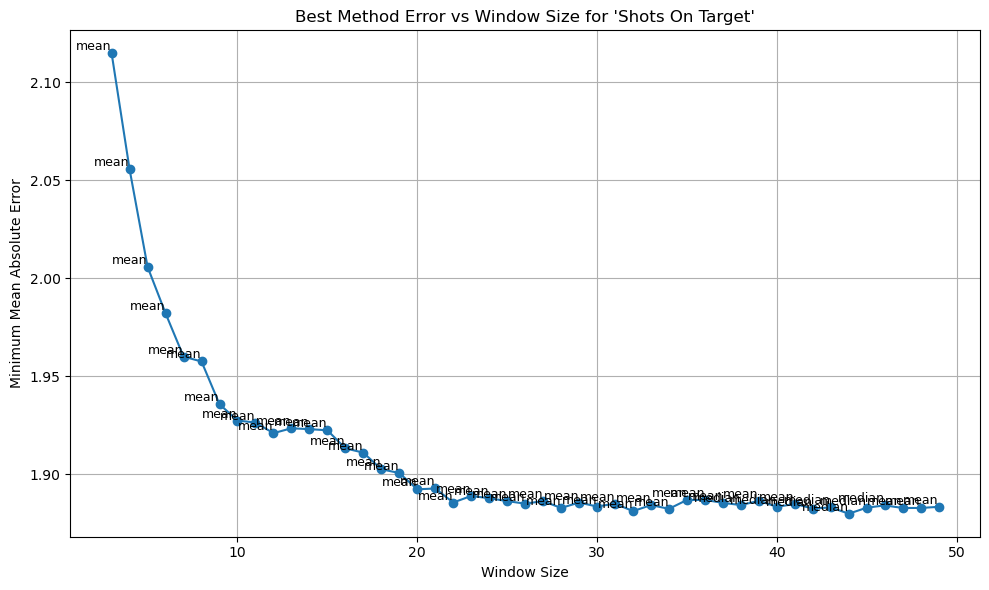

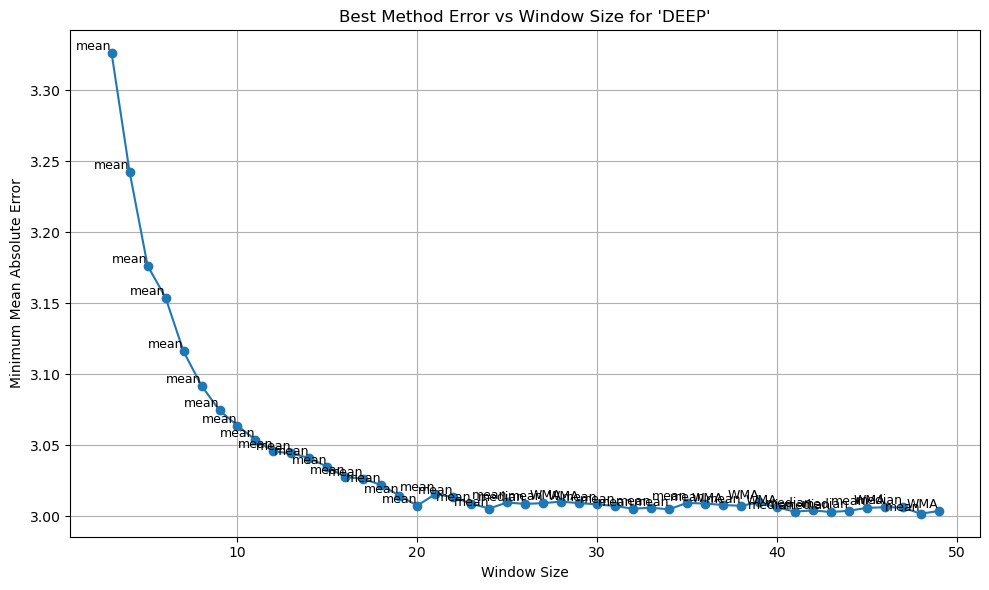

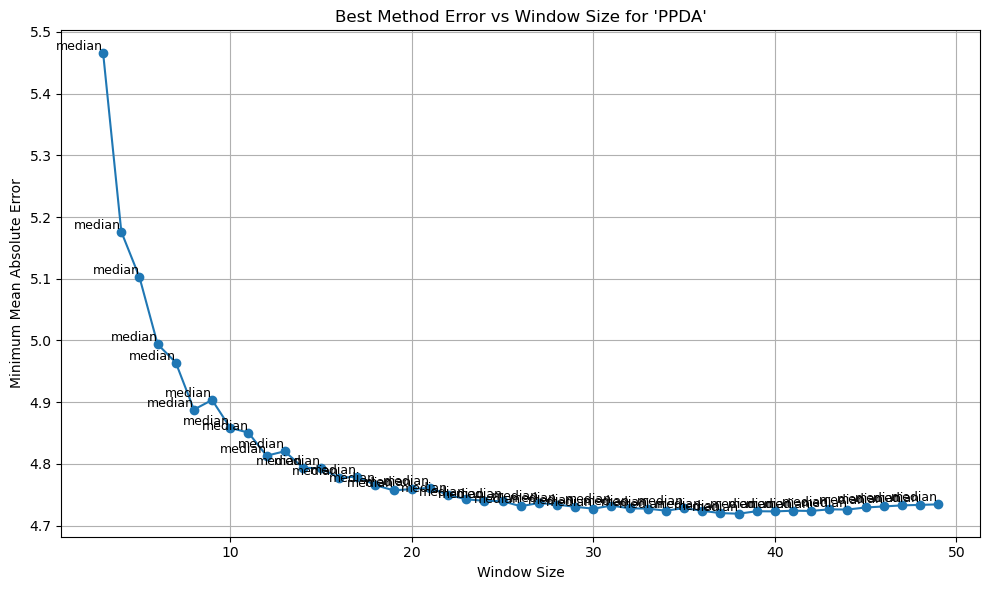

In [278]:
# --- Error Analysis Function ---
def error_analysis(df, features_to_aggregate, methods):
    errors_methods = [f'{feature}_{method}_error' for feature in features_to_aggregate for method in methods]
    errors_df = df[errors_methods].mean().reset_index()
    errors_df.columns = ['method_feature', 'mean_error']

    errors_df['feature'] = errors_df['method_feature'].apply(
        lambda x: re.search(r'(.+?)_\w+_error', x).group(1)
    )
    errors_df['method'] = errors_df['method_feature'].apply(
        lambda x: re.search(r'_(\w+)_error', x).group(1)
    )

    return errors_df[['feature', 'method', 'mean_error']]

# --- Run aggregation for multiple windows ---
aggregated_dfs = {}
for window in range(3, 50):  # Windows 3 to 7
    aggregated = aggregation_with_error_analysis(team_stats_df, features_to_aggregate, window=window)
    aggregated_dfs[window] = aggregated

# --- Collect and combine all errors ---
all_errors = []
for window, df in aggregated_dfs.items():
    error_df = error_analysis(df, features_to_aggregate, methods)
    error_df['window'] = window
    all_errors.append(error_df)

error_window_df = pd.concat(all_errors, ignore_index=True)

# Find best method per window per feature
best_errors = (
    error_window_df
    .sort_values(by="mean_error")
    .groupby(["feature", "window"])
    .first()
    .reset_index()
)

# Plotting
for feature in features_to_aggregate:
    subset = best_errors[best_errors["feature"] == feature]
    plt.figure(figsize=(10, 6))
    plt.plot(subset["window"], subset["mean_error"], marker='o')
    
    # Annotate each point with the best method
    for _, row in subset.iterrows():
        plt.text(row["window"], row["mean_error"], row["method"], fontsize=9, ha='right', va='bottom')
    
    plt.title(f"Best Method Error vs Window Size for '{feature}'")
    plt.xlabel("Window Size")
    plt.ylabel("Minimum Mean Absolute Error")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [279]:
aggregated_dfs[20][['DEEP_mean_error']].mean()

DEEP_mean_error    3.007602
dtype: float64

In [280]:
aggregated_dfs[20][['PPDA_median_error']].mean()

PPDA_median_error    4.759082
dtype: float64

In [281]:
aggregated_dfs[20][['Shots On Target_mean_error']].mean()

Shots On Target_mean_error    1.892251
dtype: float64

In [285]:
feature_to_window_and_method = {
    "Shots On Target": [20, "mean"],
    "DEEP": [20, "mean"],
    "PPDA": [20, "median"],
} 
def merge_aggregated_data(base_df, aggregated_dfs, feature_to_window_and_method):
    """
    Merge aggregated feature values and their errors into the base DataFrame 
    without renaming the original columns.
    """
    df = base_df.copy()

    for feature, (window, method) in feature_to_window_and_method.items():
        if window not in aggregated_dfs:
            print(f"[WARN] Window {window} not found for feature '{feature}'. Skipping.")
            continue
        
        agg_df = aggregated_dfs[window]
        agg_col = f"{feature}_{method}"
        error_col = f"{agg_col}_error"

        # Column validation
        if agg_col not in agg_df.columns or error_col not in agg_df.columns:
            print(f"[WARN] Missing columns for '{feature}' with window {window} and method '{method}'. Skipping.")
            continue

        # Merge into main DataFrame (keeping original names)
        df = df.merge(
            agg_df[['team_id', 'date', agg_col, error_col]],
            on=['team_id', 'date'],
            how='left'
        )

    return df


In [286]:
df_to_save = merge_aggregated_data(team_stats_df, aggregated_dfs, feature_to_window_and_method)

In [287]:
df_to_save.columns

Index(['id', 'date', 'team_id', 'Shots On Target', 'DEEP', 'PPDA', 'h_a',
       'Shots On Target_mean', 'Shots On Target_mean_error', 'DEEP_mean',
       'DEEP_mean_error', 'PPDA_median', 'PPDA_median_error'],
      dtype='object')

In [249]:
df_to_pivot= pd.merge(
    df_to_save,
    home_away_df,
    on=['id', 'team_id'],
    how='left'
)

In [250]:
df_to_pivot

,id,date,team_id,Shots On Target,DEEP,PPDA,xG,h_a_x,Shots On Target_mean,Shots On Target_mean_error,DEEP_mean,DEEP_mean_error,PPDA_median,PPDA_median_error,xG_mean,xG_mean_error,h_a_y
0,81,2015-08-08 15:45:00,89,1,4,13.8261,0.627539,h,1.0,0.0,4.0,0.0,13.82610,0.00000,0.627539,0.000000,h
1,82,2015-08-08 18:00:00,73,2,11,6.9000,0.876106,h,2.0,0.0,11.0,0.0,6.90000,0.00000,0.876106,0.000000,h
2,83,2015-08-08 18:00:00,72,5,5,6.6500,0.604226,h,5.0,0.0,5.0,0.0,6.65000,0.00000,0.604226,0.000000,h
3,84,2015-08-08 18:00:00,75,8,5,10.8800,2.568030,h,8.0,0.0,5.0,0.0,10.88000,0.00000,2.568030,0.000000,h
4,85,2015-08-08 18:00:00,79,6,5,5.7368,1.130760,h,6.0,0.0,5.0,0.0,5.73680,0.00000,1.130760,0.000000,h
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6835,22270,2024-05-19 15:00:00,71,2,0,30.3000,0.598846,a,5.0,3.0,9.0,9.0,13.93215,16.36785,1.713954,1.115108,a
6836,22271,2024-05-19 15:00:00,229,3,1,16.6000,0.731254,a,4.0,1.0,6.0,5.0,13.35275,3.24725,1.382576,0.651322,a
6837,22272,2024-05-19 15:00:00,228,7,5,10.5000,1.115980,a,5.0,2.0,8.0,3.0,12.26420,1.76420,1.452911,0.336931,a
6838,22273,2024-05-19 15:00:00,81,2,0,63.0000,0.240159,a,4.0,2.0,4.0,4.0,14.27500,48.72500,1.448837,1.208678,a


<Axes: title={'center': 'Team 89 DEEP vs Mean DEEP'}, xlabel='date'>

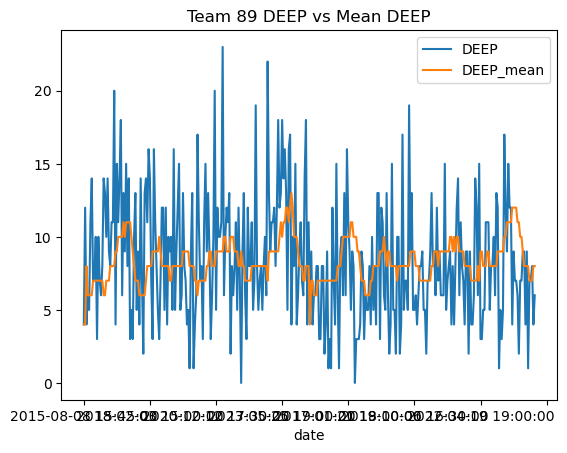

In [264]:
df_to_pivot[df_to_pivot["team_id"]==89][["DEEP", "DEEP_mean", "date"]].plot(kind = 'line', x='date', y=['DEEP', 'DEEP_mean'], title='Team 89 DEEP vs Mean DEEP')

In [208]:
df_to_pivot[df_to_pivot["team_id"]==89]

,id,date,team_id,Shots On Target,DEEP,PPDA,xG,h_a_x,Shots On Target_mean,Shots On Target_mean_error,DEEP_mean,DEEP_mean_error,PPDA_median,PPDA_median_error,xG_mean,xG_mean_error,h_a_y
0,81,2015-08-08 15:45:00,89,1,4,13.8261,0.627539,h,1.0,0.0,4.0,0.0,13.82610,0.00000,0.627539,0.000000,h
20,101,2015-08-22 15:45:00,89,8,12,4.7097,1.249100,h,2.0,6.0,4.0,8.0,11.66305,6.95335,0.643971,0.605129,h
46,127,2015-09-12 20:30:00,89,3,4,9.7778,1.462060,h,4.0,1.0,8.0,4.0,8.19830,1.57950,0.954483,0.507577,h
65,146,2015-09-26 18:00:00,89,7,6,6.4286,2.897100,h,4.0,3.0,6.0,0.0,9.63890,3.21030,1.155197,1.741903,h
98,179,2015-10-25 18:05:00,89,1,5,7.0000,0.391754,h,4.0,3.0,6.0,1.0,9.50000,2.50000,1.371816,0.980062,h
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6750,22187,2024-03-30 20:00:00,89,5,7,7.2000,0.989565,a,5.0,0.0,7.0,0.0,12.42205,5.22205,1.632402,0.642837,a
6762,22201,2024-04-04 19:15:00,89,5,7,12.7200,1.566860,a,5.0,0.0,7.0,0.0,12.16070,0.55930,1.608787,0.041927,a
6778,22215,2024-04-13 16:30:00,89,2,8,10.8125,1.522740,a,5.0,3.0,7.0,1.0,12.64570,1.83320,1.657270,0.134530,a
6816,22250,2024-05-06 19:00:00,89,2,4,11.6500,0.341417,a,6.0,4.0,8.0,4.0,12.16070,0.51070,1.800307,1.458890,a


<Axes: title={'center': 'Team 89 DEEP vs Mean DEEP Error'}, xlabel='date'>

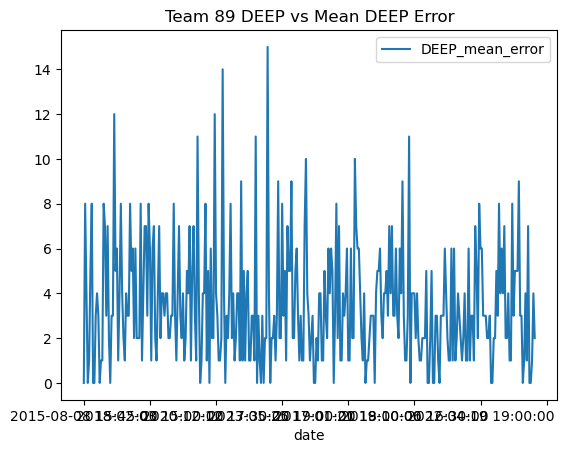

In [259]:
df_to_pivot[df_to_pivot["team_id"]==89][['DEEP_mean_error','date']].plot(kind = 'line', x='date', y=[ 'DEEP_mean_error'], title='Team 89 DEEP vs Mean DEEP Error')

<Axes: title={'center': 'Team 89 PPDA vs Median PPDA'}, xlabel='date'>

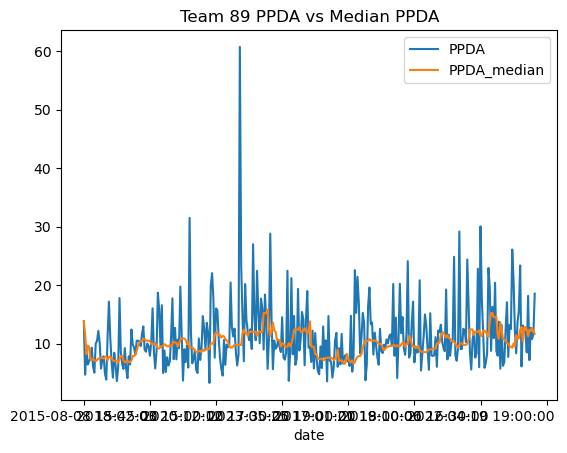

In [258]:
df_to_pivot[df_to_pivot['team_id'] == 89][["PPDA", "PPDA_median", "date"]].plot(kind = 'line', x='date', y=['PPDA', 'PPDA_median'], title='Team 89 PPDA vs Median PPDA')

<Axes: title={'center': 'Team 89 Shots On Target vs Mean Shots On Target'}, xlabel='date'>

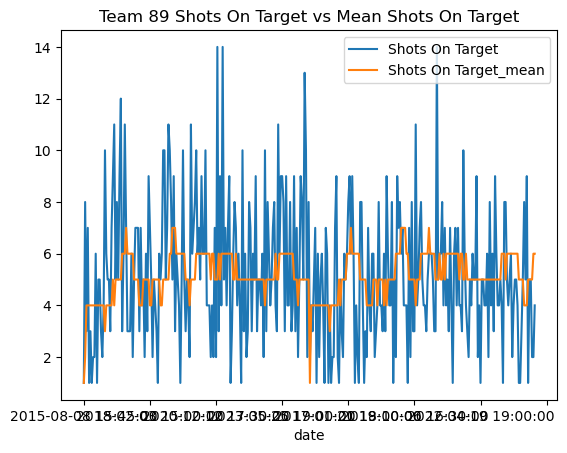

In [257]:
df_to_pivot[df_to_pivot['team_id'] == 89][["Shots On Target", "Shots On Target_mean", "date"]].plot(kind = 'line', x='date', y=['Shots On Target', 'Shots On Target_mean'], title='Team 89 Shots On Target vs Mean Shots On Target')

In [244]:
def reverse_pivot_match_df(long_df):
    """
    Converts the long-format team stats DataFrame back into the original wide format
    with 'h_' and 'a_' columns for home and away teams.
    """
    # Split into home and away using index order or a 'home' flag if available
    home_df = long_df[long_df['h_a'] == 'h'].copy()
    away_df = long_df[long_df['h_a'] == 'a'].copy()

    # Rename columns back to original wide format
    home_df = home_df.rename(columns={
        'team_id': 'h',
        'Shots On Target': 'h_shotOnTarget',
        'Shots On Target_mean': 'h_shotOnTarget_mean',
        'Shots On Target_mean_error': 'h_shotOnTarget_mean_error',
        'DEEP': 'h_deep',
        'DEEP_mean': 'h_deep_mean',
        'DEEP_mean_error': 'h_deep_mean_error',
        'PPDA': 'h_ppda',
        'PPDA_median': 'h_ppda_median',
        'PPDA_median_error': 'h_ppda_median_error',
        'xG': 'h_xg',
        'xG_mean': 'h_xg_mean',
        'xG_mean_error': 'h_xg_mean_error'
    })

    away_df = away_df.rename(columns={
        'team_id': 'a',
        'Shots On Target': 'a_shotOnTarget',
        'Shots On Target_mean': 'a_shotOnTarget_mean',
        'Shots On Target_mean_error': 'a_shotOnTarget_mean_error',
        'DEEP': 'a_deep',
        'DEEP_mean': 'a_deep_mean',
        'DEEP_mean_error': 'a_deep_mean_error',
        'PPDA': 'a_ppda',
        'PPDA_median': 'a_ppda_median',
        'PPDA_median_error': 'a_ppda_median_error',
        'xG': 'a_xg',
        'xG_mean': 'a_xg_mean',
        'xG_mean_error': 'a_xg_mean_error'
    })

    # Merge home and away back together on match id and date
    wide_df = pd.merge(
        home_df[['id', 'date', 'h', 'h_shotOnTarget', 'h_shotOnTarget_mean', 'h_shotOnTarget_mean_error', 'h_deep', 'h_deep_mean', 'h_deep_mean_error', 'h_ppda', 'h_ppda_median', 'h_ppda_median_error', 'h_xg', 'h_xg_mean', 'h_xg_mean_error']],
        away_df[['id', 'date', 'a', 'a_shotOnTarget', 'a_shotOnTarget_mean', 'a_shotOnTarget_mean_error', 'a_deep', 'a_deep_mean', 'a_deep_mean_error', 'a_ppda', 'a_ppda_median', 'a_ppda_median_error', 'a_xg', 'a_xg_mean', 'a_xg_mean_error']],
        on=['id', 'date'],
        how='inner'
    )

    return wide_df


In [253]:
df_repivoted= reverse_pivot_match_df(df_to_save)

In [254]:
df_repivoted

,id,date,h,h_shotOnTarget,h_shotOnTarget_mean,h_shotOnTarget_mean_error,h_deep,h_deep_mean,h_deep_mean_error,h_ppda,...,a_shotOnTarget_mean_error,a_deep,a_deep_mean,a_deep_mean_error,a_ppda,a_ppda_median,a_ppda_median_error,a_xg,a_xg_mean,a_xg_mean_error
0,81,2015-08-08 15:45:00,89,1,1.0,0.0,4,4.0,0.0,13.8261,...,0.0,10,10.0,0.0,8.2188,8.21880,0.00000,0.674600,0.674600,0.000000
1,82,2015-08-08 18:00:00,73,2,2.0,0.0,11,11.0,0.0,6.9000,...,0.0,2,2.0,0.0,11.8462,11.84620,0.00000,0.782253,0.782253,0.000000
2,83,2015-08-08 18:00:00,72,5,5.0,0.0,5,5.0,0.0,6.6500,...,0.0,4,4.0,0.0,17.1579,17.15790,0.00000,0.557892,0.557892,0.000000
3,84,2015-08-08 18:00:00,75,8,8.0,0.0,5,5.0,0.0,10.8800,...,0.0,6,6.0,0.0,9.5556,9.55560,0.00000,1.459460,1.459460,0.000000
4,85,2015-08-08 18:00:00,79,6,6.0,0.0,5,5.0,0.0,5.7368,...,0.0,10,10.0,0.0,10.6250,10.62500,0.00000,2.109750,2.109750,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3415,22270,2024-05-19 15:00:00,78,9,5.0,4.0,11,6.0,5.0,14.4783,...,3.0,0,9.0,9.0,30.3000,13.93215,16.36785,0.598846,1.713954,1.115108
3416,22271,2024-05-19 15:00:00,87,14,8.0,6.0,22,14.0,8.0,5.0968,...,1.0,1,6.0,5.0,16.6000,13.35275,3.24725,0.731254,1.382576,0.651322
3417,22272,2024-05-19 15:00:00,256,6,4.0,2.0,4,5.0,1.0,13.8947,...,2.0,5,8.0,3.0,10.5000,12.26420,1.76420,1.115980,1.452911,0.336931
3418,22273,2024-05-19 15:00:00,88,12,8.0,4.0,16,15.0,1.0,8.0000,...,2.0,0,4.0,4.0,63.0000,14.27500,48.72500,0.240159,1.448837,1.208678


In [288]:
df_to_save.to_csv("Data/understat_team_aggregated.csv", index=False)

In [ ]:


def aggregation_with_error_analysis(df, features_to_aggregate, window=5, discrete_features=None):
    """
    Aggregates team match data using:
    - Rolling mean
    - Linear regression
    - Exponential Moving Average (EMA)
    - Weighted Moving Average (WMA)
    - Median Aggregation
    - Weighted Ensemble (based on inverse error per method per feature)
    
    Computes prediction error for each method vs actual value.
    Returns: updated DataFrame, feature_weights dictionary
    """
    if discrete_features is None:
        discrete_features = []

    methods = [ 'mean', 'ExpoMovingAverage', 'WMA', 'median']
    df = df.copy().sort_values(by=['team_id', 'date']).reset_index(drop=True)

    # Add prediction & error columns
    for feature in features_to_aggregate:
        for method in methods + ['ensemble']:
            df[f'{feature}_{method}'] = np.nan
            df[f'{feature}_{method}_error'] = np.nan

    # --- First pass: compute method predictions ---
    for team_id, team_df in tqdm(df.groupby('team_id'), desc=f"Aggregating teams (window={window})"):
        team_df = team_df.sort_values('date').copy()
        team_df.reset_index(drop=False, inplace=True)

        for feature in features_to_aggregate:
            preds = {method: [] for method in methods}
            errors = {method: [] for method in methods}

            for i in range(len(team_df)):
                actual = team_df.loc[i, feature]
                past_values = team_df.loc[max(0, i - window):i - 1, feature].astype(float)

                if past_values.empty:
                    mean_val = expo_val = wma_val = median_val = 0
                else:
                    mean_val = past_values.mean()
                    expo_val = past_values.ewm(span=window, adjust=False).mean().iloc[-1]
                    wma_val = np.dot(past_values, np.arange(1, len(past_values)+1)) / np.sum(np.arange(1, len(past_values)+1))
                    median_val = past_values.median()


                # Clamp/round if discrete
                if feature in discrete_features:
                    values = {
                        'mean': max(0, round(mean_val)),
                        'ExpoMovingAverage': max(0, round(expo_val)),
                        'WMA': max(0, round(wma_val)),
                        'median': max(0, round(median_val))
                    }
                else:
                    values = {
                        'mean': max(0, mean_val),
                        'ExpoMovingAverage': max(0, expo_val),
                        'WMA': max(0, wma_val),
                        'median': max(0, median_val)
                    }

                for method in methods:
                    preds[method].append(values[method])
                    errors[method].append(abs(float(actual) - values[method]))

            for method in methods:
                df.loc[team_df['index'], f'{feature}_{method}'] = preds[method]
                df.loc[team_df['index'], f'{feature}_{method}_error'] = errors[method]

    # --- Compute feature-wise weights (based on inverse error) ---
    feature_weights = {}
    for feature in features_to_aggregate:
        method_errors = {
            method: df[f'{feature}_{method}_error'].mean()
            for method in methods
        }
        inv_errors = {m: 1 / e if e != 0 else 0 for m, e in method_errors.items()}
        total = sum(inv_errors.values())
        feature_weights[feature] = {
            m: inv_errors[m] / total if total > 0 else 1 / len(inv_errors)
            for m in inv_errors
        }

    # --- Final pass: compute ensemble predictions ---
    for team_id, team_df in df.groupby('team_id'):
        for feature in features_to_aggregate:
            weights = feature_weights[feature]

            for i in team_df.index:
                actual = df.at[i, feature]
                method_preds = {m: df.at[i, f'{feature}_{m}'] for m in methods}
                ensemble_val = sum(weights[m] * method_preds[m] for m in methods)
                ensemble_val = max(0, round(ensemble_val)) if feature in discrete_features else max(0, ensemble_val)
                ensemble_error = abs(float(actual) - ensemble_val)

                df.at[i, f'{feature}_ensemble'] = ensemble_val
                df.at[i, f'{feature}_ensemble_error'] = ensemble_error

    return df, feature_weights


In [139]:
aggregation_v2,_ = aggregation_with_error_analysis(team_stats_df, features_to_aggregate, window=9)

Aggregating teams (window=9):   0%|          | 0/33 [00:00<?, ?it/s]

Aggregating teams (window=9): 100%|██████████| 33/33 [00:02<00:00, 11.92it/s]


In [137]:
methods.remove('linear')

In [140]:
def get_ensemble_errors(df, features_to_aggregate):
    """
    Returns the average ensemble prediction error per feature.
    """
    ensemble_errors = {
        feature: df[f"{feature}_ensemble_error"].mean()
        for feature in features_to_aggregate
    }

    return pd.DataFrame.from_dict(
        ensemble_errors, orient='index', columns=['ensemble_mean_error']
    ).reset_index().rename(columns={'index': 'feature'})

# Example usage
ensemble_error_df = get_ensemble_errors(aggregation_v2, features_to_aggregate)

print(ensemble_error_df.sort_values(by='ensemble_mean_error'))


           feature  ensemble_mean_error
0  Shots On Target             1.977434
1             DEEP             3.110876
2             PPDA             5.070983


In [144]:
error_analysis(aggregated_dfs[9], features_to_aggregate, methods)

,feature,method,mean_error
0,Shots On Target,mean,1.954825
1,Shots On Target,ExpoMovingAverage,1.985234
2,Shots On Target,WMA,1.983041
3,Shots On Target,median,1.992251
4,DEEP,mean,3.098684
5,DEEP,ExpoMovingAverage,3.121053
6,DEEP,WMA,3.130994
7,DEEP,median,3.161988
8,PPDA,mean,5.168858
9,PPDA,ExpoMovingAverage,5.226707


In [ ]:
def aggregation_with_error_analysis(df, features_to_aggregate, window=5, discrete_features=None):
    """
    Aggregates team match data using:
    - Rolling mean
    - Exponential Moving Average (EMA)
    - Weighted Moving Average (WMA)
    - Median Aggregation
    - Top-2 Weighted Ensemble (based on inverse error per method per feature)
    
    Computes prediction error for each method vs actual value.
    Returns: updated DataFrame, feature_weights dictionary
    """
    if discrete_features is None:
        discrete_features = []

    methods = ['mean', 'ExpoMovingAverage', 'WMA', 'median']
    df = df.copy().sort_values(by=['team_id', 'date']).reset_index(drop=True)

    for feature in features_to_aggregate:
        for method in methods + ['ensemble']:
            df[f'{feature}_{method}'] = np.nan
            df[f'{feature}_{method}_error'] = np.nan

    # --- First pass: compute base method predictions ---
    for team_id, team_df in tqdm(df.groupby('team_id'), desc=f"Aggregating teams (window={window})"):
        team_df = team_df.sort_values('date').copy()
        team_df.reset_index(drop=False, inplace=True)

        for feature in features_to_aggregate:
            preds = {method: [] for method in methods}
            errors = {method: [] for method in methods}

            for i in range(len(team_df)):
                actual = team_df.loc[i, feature]
                past_values = team_df.loc[max(0, i - window):i - 1, feature].astype(float)

                if past_values.empty:
                    actual_val = team_df.loc[i, feature]
                    mean_val = expo_val = wma_val = median_val = actual_val
                else:
                    mean_val = past_values.mean()
                    expo_val = past_values.ewm(span=window, adjust=False).mean().iloc[-1]
                    wma_val = np.dot(past_values, np.arange(1, len(past_values)+1)) / np.sum(np.arange(1, len(past_values)+1))
                    median_val = past_values.median()

                values = {
                    'mean': max(0, round(mean_val)) if feature in discrete_features else max(0, mean_val),
                    'ExpoMovingAverage': max(0, round(expo_val)) if feature in discrete_features else max(0, expo_val),
                    'WMA': max(0, round(wma_val)) if feature in discrete_features else max(0, wma_val),
                    'median': max(0, round(median_val)) if feature in discrete_features else max(0, median_val)
                }

                for method in methods:
                    preds[method].append(values[method])
                    errors[method].append(abs(float(actual) - values[method]))

            for method in methods:
                df.loc[team_df['index'], f'{feature}_{method}'] = preds[method]
                df.loc[team_df['index'], f'{feature}_{method}_error'] = errors[method]

    # --- Compute top-2 weighted ensemble weights per feature ---
    feature_weights = {}
    for feature in features_to_aggregate:
        # Mean error per method
        method_errors = {
            method: df[f'{feature}_{method}_error'].mean()
            for method in methods
        }

        # Take top 2 best methods (lowest errors)
        top_2 = sorted(method_errors.items(), key=lambda x: x[1])[:2]

        # Compute weights from inverse errors of top 2
        inv_errors = {m: 1 / e if e != 0 else 0 for m, e in top_2}
        total = sum(inv_errors.values())
        feature_weights[feature] = {
            m: inv_errors[m] / total if total > 0 else 0.5 for m in inv_errors
        }

    # --- Final pass: compute ensemble predictions using top-2 methods ---
    for team_id, team_df in df.groupby('team_id'):
        for feature in features_to_aggregate:
            weights = feature_weights[feature]

            for i in team_df.index:
                actual = df.at[i, feature]
                method_preds = {m: df.at[i, f'{feature}_{m}'] for m in weights}
                ensemble_val = sum(weights[m] * method_preds[m] for m in weights)
                ensemble_val = max(0, round(ensemble_val)) if feature in discrete_features else max(0, ensemble_val)
                ensemble_error = abs(float(actual) - ensemble_val)

                df.at[i, f'{feature}_ensemble'] = ensemble_val
                df.at[i, f'{feature}_ensemble_error'] = ensemble_error

    return df, feature_weights


In [150]:
aggregation_df, feature_weights = aggregation_with_error_analysis(team_stats_df, features_to_aggregate, window=9)
ensemble_error_df = get_ensemble_errors(aggregation_df, features_to_aggregate)


Aggregating teams (window=9):   0%|          | 0/33 [00:00<?, ?it/s]

Aggregating teams (window=9): 100%|██████████| 33/33 [00:03<00:00, 10.58it/s]


In [151]:
ensemble_error_df

,feature,ensemble_mean_error
0,Shots On Target,1.957616
1,DEEP,3.087541
2,PPDA,4.924749


In [157]:
aggregation_df

,id,date,team_id,Shots On Target,DEEP,PPDA,Shots On Target_mean,Shots On Target_mean_error,Shots On Target_ExpoMovingAverage,Shots On Target_ExpoMovingAverage_error,...,PPDA_mean,PPDA_mean_error,PPDA_ExpoMovingAverage,PPDA_ExpoMovingAverage_error,PPDA_WMA,PPDA_WMA_error,PPDA_median,PPDA_median_error,PPDA_ensemble,PPDA_ensemble_error
0,82,2015-08-08 18:00:00,71,3,2,11.8462,3.000000,0.000000,3.000000,0.000000,...,11.846200,0.000000,11.846200,0.000000,11.846200,0.000000,11.84620,0.00000,11.846200,0.000000
1,91,2015-08-14 22:45:00,71,1,3,10.0333,3.000000,2.000000,3.000000,2.000000,...,11.846200,1.812900,11.846200,1.812900,11.846200,1.812900,11.84620,1.81290,11.846200,1.812900
2,104,2015-08-22 18:00:00,71,2,6,8.4762,2.000000,0.000000,2.600000,0.600000,...,10.939750,2.463550,11.483620,3.007420,10.637600,2.161400,10.93975,2.46355,10.939750,2.463550
3,113,2015-08-29 18:00:00,71,6,12,8.6364,2.000000,4.000000,2.480000,3.520000,...,10.118567,1.482167,10.882136,2.245736,9.556900,0.920500,10.03330,1.39690,10.075077,1.438677
4,129,2015-09-13 19:00:00,71,4,5,8.4091,3.000000,1.000000,3.184000,0.816000,...,9.748025,1.338925,10.432989,2.023889,9.188700,0.779600,9.33485,0.92575,9.537290,1.128190
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6835,22230,2024-04-20 14:00:00,256,3,6,11.1250,3.666667,0.666667,3.682913,0.682913,...,15.130656,4.005656,16.962534,5.837534,17.059338,5.934338,13.66670,2.54170,14.383981,3.258981
6836,22244,2024-04-27 14:00:00,256,6,6,9.5333,3.666667,2.333333,3.814766,2.185234,...,15.000100,5.466800,15.978462,6.445162,16.258207,6.724907,13.66670,4.13340,14.320014,4.786714
6837,22252,2024-05-03 19:00:00,256,5,3,10.7727,3.777778,1.222222,3.849160,1.150840,...,14.540833,3.768133,14.886274,4.113574,15.164847,4.392147,11.12500,0.35230,12.798625,2.025925
6838,22263,2024-05-11 14:00:00,256,1,5,9.7407,4.111111,3.111111,4.347763,3.347763,...,14.056322,4.315622,13.257138,3.516438,14.411220,4.670520,10.77270,1.03200,12.381547,2.640847


In [154]:
error_analysis(aggregation_df, features_to_aggregate, methods)

,feature,method,mean_error
0,Shots On Target,mean,1.954689
1,Shots On Target,ExpoMovingAverage,1.977341
2,Shots On Target,WMA,1.980806
3,Shots On Target,median,1.973904
4,DEEP,mean,3.082655
5,DEEP,ExpoMovingAverage,3.108340
6,DEEP,WMA,3.119190
7,DEEP,median,3.137354
8,PPDA,mean,5.104441
9,PPDA,ExpoMovingAverage,5.162290


In [155]:
aggregation_df.columns

Index(['id', 'date', 'team_id', 'Shots On Target', 'DEEP', 'PPDA',
       'Shots On Target_mean', 'Shots On Target_mean_error',
       'Shots On Target_ExpoMovingAverage',
       'Shots On Target_ExpoMovingAverage_error', 'Shots On Target_WMA',
       'Shots On Target_WMA_error', 'Shots On Target_median',
       'Shots On Target_median_error', 'Shots On Target_ensemble',
       'Shots On Target_ensemble_error', 'DEEP_mean', 'DEEP_mean_error',
       'DEEP_ExpoMovingAverage', 'DEEP_ExpoMovingAverage_error', 'DEEP_WMA',
       'DEEP_WMA_error', 'DEEP_median', 'DEEP_median_error', 'DEEP_ensemble',
       'DEEP_ensemble_error', 'PPDA_mean', 'PPDA_mean_error',
       'PPDA_ExpoMovingAverage', 'PPDA_ExpoMovingAverage_error', 'PPDA_WMA',
       'PPDA_WMA_error', 'PPDA_median', 'PPDA_median_error', 'PPDA_ensemble',
       'PPDA_ensemble_error'],
      dtype='object')

In [156]:
df_to_pivot_back= aggregation_df[['id', 'date', 'team_id', 'Shots On Target', 'DEEP', 'PPDA', 'Shots On Target_mean',
                            'Shots On Target_mean_error', 'DEEP_mean', 'DEEP_mean_error', 'PPDA_median', 'PPDA_median_error']]

In [ ]:
df_to_pivot_back

In [ ]:
aggregated_df[columns].to_csv('Data/understat_roster_aggregated.csv', index=False)